# Swiss Electricity Demand Forecasting — Initial Data Inspection

## Objective
Develop a system to forecast next-day hourly end-user electricity
consumption in the Swiss control area.

## Data source
- Publisher: Swissgrid
- File: `EnergieUebersichtCH-2024.xlsx`
- Sheet: `Zeitreihen0h15`
- Year: 2024
- Original resolution: 15-minute intervals
- Original energy unit: kWh
- Geographic coverage: Swiss control area, which does not exactly
  match Switzerland’s national borders.

## Prediction target
`end_user_energy_mwh` represents electricity consumed by end users
during each one-hour interval, measured in MWh.

It excludes the additional components included in total consumption:
pumped-storage pumping, power plants’ own consumption, and grid losses.

## Time handling
Timestamps are interpreted in the `Europe/Zurich` timezone and
converted to UTC.

- UTC provides an unambiguous timeline for checking and aggregating intervals.
- Swiss local time provides meaningful hour, weekday, and month features.
- Repeated local timestamps during the autumn clock change are preserved:
  they represent different moments with different UTC offsets.

## Working assumption
Original timestamps are assumed to label interval ends.
For example, `01:00` represents consumption from `00:45` to `01:00`.

The file’s start and end timestamps support this interpretation,
but the documentation inspected so far does not explicitly confirm it.
This assumption requires verification before final modeling.

## Preparation and validation
- Loaded 35,136 quarter-hour observations.
- Checked missing values, zeros, negative values, and timestamp continuity.
- Aggregated end-user energy into 8,784 hourly observations.
- Confirmed four quarter-hour readings per hour.
- Verified that aggregation preserved total energy: approximately 53.369 TWh.
- Confirmed 23 hours on the spring clock-change day and 25 in autumn.

Hourly observations are labelled by their interval start.

## Scope and limitations
This notebook prepares and explores historical data. It does not
yet train a forecasting model or evaluate prediction accuracy.

2024 is used for development and exploration. A separate later period
will be needed for final evaluation.

Observed patterns are descriptive and do not establish their causes.
Historical publication delays and revisions must be considered before
using consumption data as forecasting inputs.

In [1]:
import sys
from pathlib import Path

import pandas as pd

print("Python:", sys.executable)
print("pandas:", pd.__version__)
print("Working directory:", Path.cwd())

Python: C:\Users\mihai\Projects\swiss-energy-forecast\.venv\Scripts\python.exe
pandas: 3.0.6
Working directory: C:\Users\mihai\Projects\swiss-energy-forecast\notebooks


In [2]:
# The notebook runs inside "notebooks", so its parent is the project folder.
project_dir = Path.cwd().parent
raw_dir = project_dir / "data" / "raw"

print("Data folder:", raw_dir)
print("Folder exists:", raw_dir.exists())

excel_files = sorted(raw_dir.glob("*.xlsx"))

print("Excel files found:", len(excel_files))
for file in excel_files:
    print(file.name)
    

Data folder: C:\Users\mihai\Projects\swiss-energy-forecast\data\raw
Folder exists: True
Excel files found: 1
EnergieUebersichtCH-2024.xlsx


In [3]:
file_path = raw_dir / "EnergieUebersichtCH-2024.xlsx"

workbook = pd.ExcelFile(file_path)

print("Available sheets:")
for sheet_name in workbook.sheet_names:
    print("-", sheet_name)
    

Available sheets:
- Einstellungen
- Datetime
- Uebersicht
- Zeitreihen0h15


In [4]:
preview = pd.read_excel(
    workbook,
    sheet_name="Zeitreihen0h15",
    header=None,
    nrows=15
)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", 120
):
    display(preview)
    

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64
0,NaN,Summe endverbrauchte Energie Regelblock Schweiz\nTotal energy consumed by end users in the Swiss controlblock,Summe produzierte Energie Regelblock Schweiz\nTotal energy production Swiss controlblock,Summe verbrauchte Energie Regelblock Schweiz\nTotal energy consumption Swiss controlblock,Netto Ausspeisung aus dem Übertragungsnetz Schweiz\nNet outflow of the Swiss transmission grid,Vertikale Einspeisung ins Übertragungsnetz Schweiz\nGrid feed-in Swiss transmission grid,Positive Sekundär-Regelenergie\nPositive secundary control energy,Negative Sekundär-Regelenergie\nNegative secundary control energy,Positive Tertiär-Regelenergie\nPositive tertiary control energy,Negative Tertiär-Regelenergie\nNegative tertiary control energy,Verbundaustausch CH->AT\nCross Border Exchange CH->AT,Verbundaustausch AT->CH\nCross Border Exchange AT->CH,Verbundaustausch CH->DE\nCross Border Exchange CH->DE,Verbundaustausch DE->CH\nCross Border Exchange DE->CH,Verbundaustausch CH->FR\nCross Border Exchange CH->FR,Verbundaustausch FR->CH\nCross Border Exchange FR->CH,Verbundaustausch CH->IT\nCross Border Exchange CH->IT,Verbundaustausch IT->CH\nCross Border Exchange IT->CH,Transit,Import,Export,Durchschnittliche positive Sekundär-Regelenergie Preise\nAverage positive secondary control energy prices,Durchschnittliche negative Sekundär-Regelenergie Preise\nAverage negative secondary control energy prices,Durchschnittliche positive Tertiär-Regelenergie Preise\nAverage positive tertiary control energy prices,Durchschnittliche negative Tertiär-Regelenergie Preise\nAverage negative tertiary control energy prices,Produktion Kanton AG\nProduction Canton AG,Verbrauch Kanton AG\nConsumption Canton AG,Produktion Kanton FR\nProduction Canton FR,Verbrauch Kanton FR\nConsumption Canton FR,Produktion Kanton GL\nProduction Canton GL,Verbrauch Kanton GL\nConsumption Canton GL,Produktion Kanton GR\nProduction Canton GR,Verbrauch Kanton GR\nConsumption Canton GR,Produktion Kanton LU\nProduction Canton LU,Verbrauch Kanton LU\nConsumption Canton LU,Produktion Kanton NE\nProduction Canton NE,Verbrauch Kanton NE\nConsumption Canton NE,Produktion Kanton SO\nProduction Canton SO,Verbrauch Kanton SO\nConsumption Canton SO,Produktion Kanton SG\nProduction Canton SG,Verbrauch Kanton SG\nConsumption Canton SG,Produktion Kanton TI\nProduction Canton TI,Verbrauch Kanton TI\nConsumption Canton TI,Produktion Kanton TG\nProduction Canton TG,Verbrauch Kanton TG\nConsumption Canton TG,Produktion Kanton VS\nProduction Canton VS,Verbrauch Kanton VS\nConsumption Canton VS,"Produktion Kantone AI, AR\nProduction Cantons AI, AR","Verbrauch Kantone AI, AR\nConsumption Cantons AI, AR","Produktion Kantone BL, BS\nProduction Cantons BL, BS","Verbrauch Kantone BL, BS\nConsumption Cantons BL, BS","Produktion Kantone BE, JU\nProduction Cantons BE, JU","Verbrauch Kantone BE, JU\nConsumption Cantons BE, JU","Produktion Kantone SZ, ZG\nProduction Cantons SZ, ZG","Verbrauch Kantone SZ, ZG\nConsumption Cantons SZ, ZG","Produktion Kantone OW, NW, UR\nProduction Cantons OW, NW, UR","Verbrauch Kantone OW, NW, UR\nConsumption Cantons OW, NW, UR","Produktion Kantone GE, VD\nProduction Cantons GE, VD","Verbrauch Kantone GE, VD\nConsumption Cantons GE, VD","Produktion Kantone SH, ZH\nProduction Cantons SH, ZH","Verbrauch Kantone SH, ZH\nConsumption Cantons SH, ZH",Produktion Kantonsübergreifend\nProduction across Cantons,Verbrauch Kantonsübergreifend\nConsumption across Cantons,Produktion Regelzone CH - Ausländische Gebiete\nProduction control area CH - foreign territories,Verbrauch Regelzone CH - Ausländische Gebiete\nConsumption control area CH - foreign territories
1,Zeitstempel,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,Euro/MWh,Euro/MWh,Euro/MWh,Euro/MWh,kWh,kWh,kWh,kWh,kWh,kWh,kWh,k

In [5]:
df = pd.read_excel(
    workbook,
    sheet_name="Zeitreihen0h15",
    skiprows=2,
    header=None,
    usecols="A:D",
    names=[
        "timestamp_raw",
        "end_user_energy_kwh",
        "production_energy_kwh",
        "total_consumption_energy_kwh",
    ],
)

display(df.head())
print("Rows and columns:", df.shape)
df.info()
display(df.tail())

,timestamp_raw,end_user_energy_kwh,production_energy_kwh,total_consumption_energy_kwh
0,01.01.2024 00:15,1.443842e+06,1296448.710,1.939192e+06
1,01.01.2024 00:30,1.442366e+06,1294126.969,1.921878e+06
2,01.01.2024 00:45,1.432568e+06,1289417.659,1.914425e+06
3,01.01.2024 01:00,1.420472e+06,1284384.421,1.917196e+06
4,01.01.2024 01:15,1.445856e+06,1291409.092,1.970522e+06


Rows and columns: (35136, 4)
<class 'pandas.DataFrame'>
RangeIndex: 35136 entries, 0 to 35135
Data columns (total 4 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   timestamp_raw                 35136 non-null  str    
 1   end_user_energy_kwh           35136 non-null  float64
 2   production_energy_kwh         35136 non-null  float64
 3   total_consumption_energy_kwh  35136 non-null  float64
dtypes: float64(3), str(1)
memory usage: 1.1 MB


,timestamp_raw,end_user_energy_kwh,production_energy_kwh,total_consumption_energy_kwh
35131,31.12.2024 23:00,1.658572e+06,1394786.537,1914907.706
35132,31.12.2024 23:15,1.678174e+06,1396248.145,1918393.551
35133,31.12.2024 23:30,1.659394e+06,1376701.237,1896931.611
35134,31.12.2024 23:45,1.649247e+06,1368492.955,1884667.300
35135,01.01.2025 00:00,1.634796e+06,1351933.900,1765309.010


In [6]:
# Make the project's src folder available for imports.
src_dir = str(project_dir / "src")

if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

from preparation import load_quarter_hour_data

# Compare raw data before later cells add timestamp columns to df.
loaded_df = load_quarter_hour_data(file_path)
pd.testing.assert_frame_equal(df, loaded_df)

print("PASS: The function matches the original loading code.")
print("Rows and columns:", loaded_df.shape)


PASS: The function matches the original loading code.
Rows and columns: (35136, 4)


In [7]:
# Preserve the original text and create a separate datetime column.
df["timestamp"] = pd.to_datetime(
    df["timestamp_raw"],
    format="%d.%m.%Y %H:%M",
    errors="raise",
)

print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

print(
    "Repeated timestamp labels:",
    df["timestamp"].duplicated().sum(),
)

# Keep the original row order when checking consecutive intervals.
time_steps = df["timestamp"].diff()

print("\nTime differences between consecutive rows:")
print(time_steps.value_counts())

# Show any step other than 15 minutes, excluding the first row.
unusual_steps = time_steps.notna() & (
    time_steps != pd.Timedelta(minutes=15)
)

display(
    df.loc[unusual_steps, ["timestamp_raw", "timestamp"]]
    .assign(time_difference=time_steps[unusual_steps])
)

First timestamp: 2024-01-01 00:15:00
Last timestamp: 2025-01-01 00:00:00
Repeated timestamp labels: 4

Time differences between consecutive rows:
timestamp
0 days 00:15:00      35133
0 days 01:15:00          1
-1 days +23:15:00        1
Name: count, dtype: int64


,timestamp_raw,timestamp,time_difference
8647,31.03.2024 03:00,2024-03-31 03:00:00,0 days 01:15:00
28807,27.10.2024 02:00,2024-10-27 02:00:00,-1 days +23:15:00


In [8]:
# Attach the Swiss timezone while preserving the original row order.
df["timestamp_local"] = df["timestamp"].dt.tz_localize(
    "Europe/Zurich",
    ambiguous="infer",
    nonexistent="raise",
)

# Represent the same moments in UTC, which has no seasonal clock changes.
df["timestamp_utc"] = df["timestamp_local"].dt.tz_convert("UTC")

utc_steps = df["timestamp_utc"].diff().dropna()

print("Duplicate UTC timestamps:", df["timestamp_utc"].duplicated().sum())
print("Chronological order:", df["timestamp_utc"].is_monotonic_increasing)
print("All steps are 15 minutes:", utc_steps.eq(pd.Timedelta(minutes=15)).all())

# Inspect both occurrences of the repeated autumn hour.
repeated_labels = df["timestamp"].duplicated(keep=False)

display(
    df.loc[
        repeated_labels,
        ["timestamp_raw", "timestamp_local", "timestamp_utc"],
    ]
)


Duplicate UTC timestamps: 0
Chronological order: True
All steps are 15 minutes: True


,timestamp_raw,timestamp_local,timestamp_utc
28803,27.10.2024 02:00,2024-10-27 02:00:00+02:00,2024-10-27 00:00:00+00:00
28804,27.10.2024 02:15,2024-10-27 02:15:00+02:00,2024-10-27 00:15:00+00:00
28805,27.10.2024 02:30,2024-10-27 02:30:00+02:00,2024-10-27 00:30:00+00:00
28806,27.10.2024 02:45,2024-10-27 02:45:00+02:00,2024-10-27 00:45:00+00:00
28807,27.10.2024 02:00,2024-10-27 02:00:00+01:00,2024-10-27 01:00:00+00:00
28808,27.10.2024 02:15,2024-10-27 02:15:00+01:00,2024-10-27 01:15:00+00:00
28809,27.10.2024 02:30,2024-10-27 02:30:00+01:00,2024-10-27 01:30:00+00:00
28810,27.10.2024 02:45,2024-10-27 02:45:00+01:00,2024-10-27 01:45:00+00:00


In [9]:
energy_cols = [
    "end_user_energy_kwh",
    "production_energy_kwh",
    "total_consumption_energy_kwh",
]

# Summarize the distribution of each energy measure.
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(
        df[energy_cols].describe(
            percentiles=[0.01, 0.50, 0.99]
        ).T
    )

# Count values that may need investigation.
quality_checks = pd.DataFrame({
    "missing": df[energy_cols].isna().sum(),
    "zero": df[energy_cols].eq(0).sum(),
    "negative": df[energy_cols].lt(0).sum(),
})

display(quality_checks)

# Check whether total consumption is ever below end-user consumption.
below_end_user = (
    df["total_consumption_energy_kwh"]
    < df["end_user_energy_kwh"]
)

print("Total consumption below end-user consumption:", below_end_user.sum())

display(
    df.loc[below_end_user, ["timestamp_local"] + energy_cols].head(10)
)

,count,mean,std,min,1%,50%,99%,max
end_user_energy_kwh,"35,136.00","1,518,928.99","287,095.13","892,472.31","1,000,143.01","1,499,356.38","2,241,601.46","2,366,413.53"
production_energy_kwh,"35,136.00","2,150,649.00","572,151.14","1,161,932.46","1,267,223.27","2,062,525.78","3,442,070.84","3,849,403.43"
total_consumption_energy_kwh,"35,136.00","1,753,947.04","266,541.14","1,060,860.08","1,182,886.76","1,765,574.50","2,380,283.55","2,503,510.41"


,missing,zero,negative
end_user_energy_kwh,0,0,0
production_energy_kwh,0,0,0
total_consumption_energy_kwh,0,0,0


Total consumption below end-user consumption: 0


,timestamp_local,end_user_energy_kwh,production_energy_kwh,total_consumption_energy_kwh


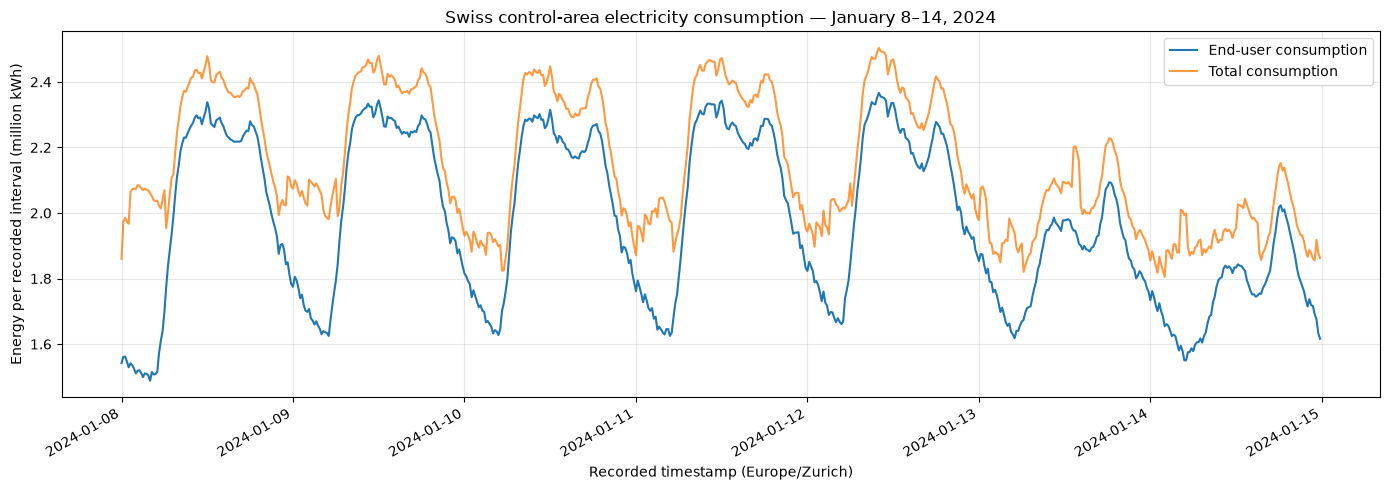

In [10]:
import matplotlib.pyplot as plt

# Select timestamps from January 8 up to, but not including, January 15.
week_mask = (
    (df["timestamp_local"] >= "2024-01-08")
    & (df["timestamp_local"] < "2024-01-15")
)

week = df.loc[week_mask]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    week["timestamp_local"],
    week["end_user_energy_kwh"] / 1_000_000,
    label="End-user consumption",
)

ax.plot(
    week["timestamp_local"],
    week["total_consumption_energy_kwh"] / 1_000_000,
    label="Total consumption",
    alpha=0.8,
)

ax.set_title("Swiss control-area electricity consumption — January 8–14, 2024")
ax.set_xlabel("Recorded timestamp (Europe/Zurich)")
ax.set_ylabel("Energy per recorded interval (million kWh)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


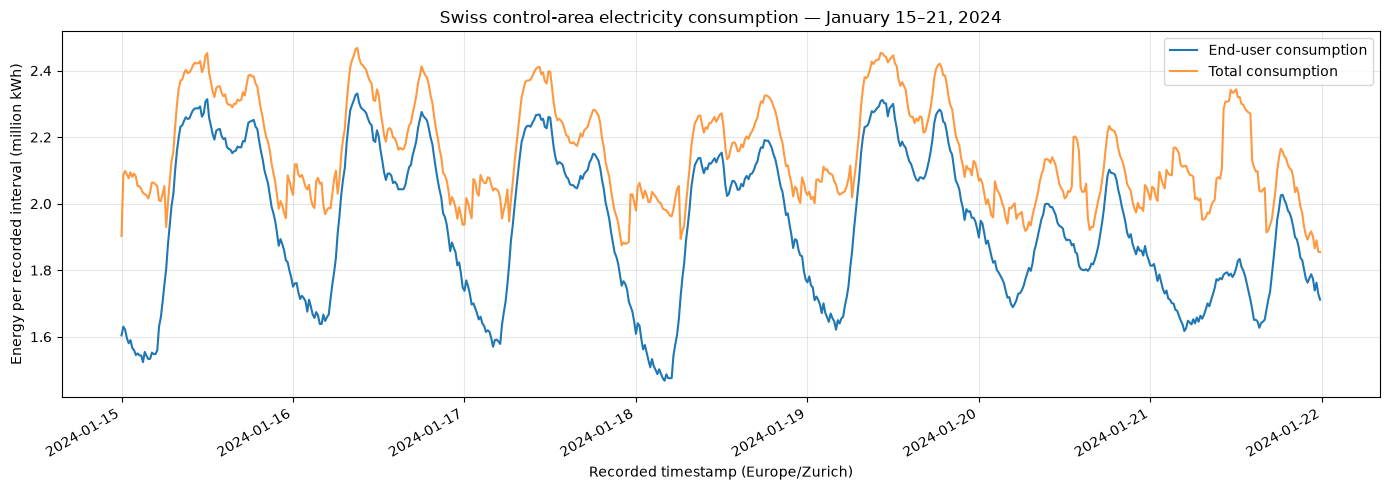

In [11]:
import matplotlib.pyplot as plt

# Select timestamps from January 15 up to, but not including, January 22.
week_mask = (
    (df["timestamp_local"] >= "2024-01-15")
    & (df["timestamp_local"] < "2024-01-22")
)

week = df.loc[week_mask]

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    week["timestamp_local"],
    week["end_user_energy_kwh"] / 1_000_000,
    label="End-user consumption",
)

ax.plot(
    week["timestamp_local"],
    week["total_consumption_energy_kwh"] / 1_000_000,
    label="Total consumption",
    alpha=0.8,
)

ax.set_title("Swiss control-area electricity consumption — January 15–21, 2024")
ax.set_xlabel("Recorded timestamp (Europe/Zurich)")
ax.set_ylabel("Energy per recorded interval (million kWh)")
ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [12]:
comparison = (
    week.assign(recorded_date=week["timestamp_local"].dt.date)
    .groupby("recorded_date")[
        ["end_user_energy_kwh", "total_consumption_energy_kwh"]
    ]
    .agg(["mean", "max"])
)

# Display Saturday and Sunday, in million kWh per interval.
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(comparison.tail(2) / 1_000_000)

end_user_energy_kwh       total_consumption_energy_kwh      
                             mean   max                         mean   max
recorded_date                                                             
2024-01-20                  1.878 2.102                        2.046 2.234
2024-01-21                  1.763 2.027                        2.083 2.344

1. Observation : The end consumption was higher on Saturday than Sunday, however the total consumption was higher on Sunday than Saturday. 2. Limitations : The limitations on why two January weeks cannot establish weekend pattern depends on the weather and how much sunlight there was and were people outside or inside. 3. We must define the prediction target precisely because end-user consumption and total consumption can behave differently. In our weekend comparison, they moved in opposite directions. 

In [13]:
for sheet_name, row_limit in [
    ("Einstellungen", 30),
    ("Datetime", 8),
]:
    print(f"\n--- {sheet_name} ---")

    metadata = pd.read_excel(
        workbook,
        sheet_name=sheet_name,
        header=None,
        nrows=row_limit,
    )

    # Hide entirely empty rows and columns in this preview.
    metadata = metadata.dropna(how="all").dropna(axis=1, how="all")

    with pd.option_context(
        "display.max_columns", None,
        "display.max_colwidth", 200,
    ):
        display(metadata)


--- Einstellungen ---


,0,2,3,4,5,6,7,14,15,16,17,18,19,20,21
0,Energieübersicht Schweiz 2024,NaN,NaN,NaN,NaN,NaN,NaT,1,1.0,2024.0,0.0,0.0,kW / kWh,Frühstes Datum,2024-01-01 00:00:00
1,Energy Statistic Switzerland 2024,NaN,NaN,NaN,NaN,NaN,NaT,2,2.0,2025.0,1.0,15.0,MW / MWh,Spätestes Datum,2025-01-01 00:00:00
2,NaN,NaN,NaN,NaN,NaN,NaN,NaT,3,3.0,NaN,2.0,30.0,NaN,Faktor:,1
3,NaN,NaN,NaN,NaN,NaN,NaN,NaT,4,4.0,NaN,3.0,45.0,NaN,Prefix:,M
4,Betrachtungszeitraum | Observation Period,NaN,NaN,NaN,NaN,NaN,NaT,5,5.0,NaN,4.0,NaN,NaN,anzMonate,12
5,NaN,NaN,NaN,NaN,NaN,NaN,NaT,6,6.0,NaN,5.0,NaN,NaN,NaN,NaN
6,NaN,DD,MM,YYYY,hh,min,NaT,7,7.0,NaN,6.0,NaN,NaN,NaN,NaN
7,Von | From:,1,1,2024,0,0,2024-01-01,8,8.0,NaN,7.0,NaN,NaN,NaN,NaN
8,Bis | To:,1,1,2025,0,0,2025-01-01,9,9.0,NaN,8.0,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaT,10,10.0,NaN,9.0,NaN,NaN,NaN,NaN



--- Datetime ---


,0
1,Zeitstempel 0h15
2,2024-01-01 00:15:00
3,2024-01-01 00:30:00
4,2024-01-01 00:45:00
5,2024-01-01 01:00:00
6,2024-01-01 01:15:00
7,2024-01-01 01:30:00


In [14]:
settings = pd.read_excel(
    workbook,
    sheet_name="Einstellungen",
    header=None,
    nrows=20,
)

print(settings.iloc[19, 0])

Das hier vorliegende Excel-Sheet beinhaltet die Gesamtübersicht der wichtigsten Eckdaten der Regelzone Schweiz.

Die Daten sind aggregierte Viertelstunden- oder Stundenwerte, welche zu ihrer Referenz im Blatt «Zeitreihen» abgelegt sind. Die Daten sind dieselben, wie auch von Swissgrid zu Abrechnungszwecken verwendet werden.

Nebst den Zeitreihen finden Sie auf dem Blatt «Übersicht» die Summen der jeweiligen Energiegrösse welche für den eingestellten Zeitraum direkt berechnet werden. Der Betrachtungszeitraum kann auf dieser Seite eingestellt werden.

Achtung: Bei MS-Excel 2003 und älter werden einige Felder nicht automatisch berechnet. Drücken Sie daher STRG+ALT+F9 nachdem Sie die Datei geöffnet haben.


In [15]:
# Working assumption: source timestamps mark interval ends.
df["interval_start_utc"] = (
    df["timestamp_utc"] - pd.Timedelta(minutes=15)
)

# Use interval starts as the time index.
energy = df.set_index("interval_start_utc")["end_user_energy_kwh"]

# Group into hours, each labelled by its start time.
hourly_groups = energy.resample("1h", closed="left", label="left")

hourly = pd.DataFrame({
    "end_user_energy_kwh": hourly_groups.sum(min_count=4),
    "interval_count": hourly_groups.count(),
})

# Convert hourly energy from kWh to MWh.
hourly["end_user_energy_mwh"] = hourly["end_user_energy_kwh"] / 1000

# Retain local time for interpretation and future calendar features.
hourly["hour_start_local"] = hourly.index.tz_convert("Europe/Zurich")

print("Number of hours:", len(hourly))
print("Intervals per hour:")
print(hourly["interval_count"].value_counts())
print("Missing hourly targets:", hourly["end_user_energy_mwh"].isna().sum())

display(hourly.head())
display(hourly.tail())


Number of hours: 8784
Intervals per hour:
interval_count
4    8784
Name: count, dtype: int64
Missing hourly targets: 0


,end_user_energy_kwh,interval_count,end_user_energy_mwh,hour_start_local
interval_start_utc,,,,
2023-12-31 23:00:00+00:00,5.739248e+06,4,5739.248154,2024-01-01 00:00:00+01:00
2024-01-01 00:00:00+00:00,5.710915e+06,4,5710.915366,2024-01-01 01:00:00+01:00
2024-01-01 01:00:00+00:00,5.576794e+06,4,5576.793738,2024-01-01 02:00:00+01:00
2024-01-01 02:00:00+00:00,5.389995e+06,4,5389.995073,2024-01-01 03:00:00+01:00
2024-01-01 03:00:00+00:00,5.235866e+06,4,5235.865674,2024-01-01 04:00:00+01:00


,end_user_energy_kwh,interval_count,end_user_energy_mwh,hour_start_local
interval_start_utc,,,,
2024-12-31 18:00:00+00:00,7.397254e+06,4,7397.253664,2024-12-31 19:00:00+01:00
2024-12-31 19:00:00+00:00,7.011775e+06,4,7011.775284,2024-12-31 20:00:00+01:00
2024-12-31 20:00:00+00:00,6.701802e+06,4,6701.801883,2024-12-31 21:00:00+01:00
2024-12-31 21:00:00+00:00,6.684293e+06,4,6684.292868,2024-12-31 22:00:00+01:00
2024-12-31 22:00:00+00:00,6.621611e+06,4,6621.610679,2024-12-31 23:00:00+01:00


In [16]:
import numpy as np

raw_total_kwh = df["end_user_energy_kwh"].sum()
hourly_total_kwh = hourly["end_user_energy_kwh"].sum()

energy_preserved = np.isclose(
    raw_total_kwh,
    hourly_total_kwh,
    rtol=1e-12,
    atol=0.01,
)

print("Total energy preserved:", energy_preserved)
print("Annual end-user energy (TWh):", raw_total_kwh / 1_000_000_000)

hours_per_day = hourly.groupby(
    hourly["hour_start_local"].dt.date
).size()

print("\nDays without exactly 24 hours:")
print(hours_per_day[hours_per_day != 24])

assert energy_preserved, "Aggregation changed the total energy."
assert hourly["interval_count"].eq(4).all(), "An hour has an unexpected count."
assert hourly["end_user_energy_mwh"].notna().all(), "An hourly target is missing."

Total energy preserved: True
Annual end-user energy (TWh): 53.369088864515874

Days without exactly 24 hours:
hour_start_local
2024-03-31    23
2024-10-27    25
dtype: int64


In [17]:
hourly["day_of_week"] = hourly["hour_start_local"].dt.dayofweek

weekday_summary = (
    hourly.groupby("day_of_week")["end_user_energy_mwh"]
    .agg(["mean", "median", "count"])
    .reindex(range(7))
)

weekday_summary.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

display(weekday_summary.round(2))


,mean,median,count
Monday,6228.17,6130.38,1272
Tuesday,6370.24,6268.73,1272
Wednesday,6402.90,6285.76,1248
Thursday,6368.24,6285.90,1248
Friday,6324.33,6191.39,1248
Saturday,5589.57,5408.89,1248
Sunday,5237.98,5088.82,1248


In [18]:
monday_mean = weekday_summary.loc["Monday", "mean"]
sunday_mean = weekday_summary.loc["Sunday", "mean"]

# Your task: use these variables to calculate the percentage difference.


In [19]:
monday_mean = weekday_summary.loc["Monday", "mean"]
sunday_mean = weekday_summary.loc["Sunday", "mean"]

percentage_difference = (
    (sunday_mean - monday_mean) / monday_mean
) * 100

print(f"Sunday versus Monday: {percentage_difference:.2f}%")

Sunday versus Monday: -15.90%


In [20]:
saturday_mean = weekday_summary.loc["Saturday", "mean"]
friday_mean = weekday_summary.loc["Friday", "mean"]

percentage_difference = (
    (saturday_mean - friday_mean) / friday_mean
) * 100

print(f"Saturday versus Friday: {percentage_difference:.2f}%")

Saturday versus Friday: -11.62%


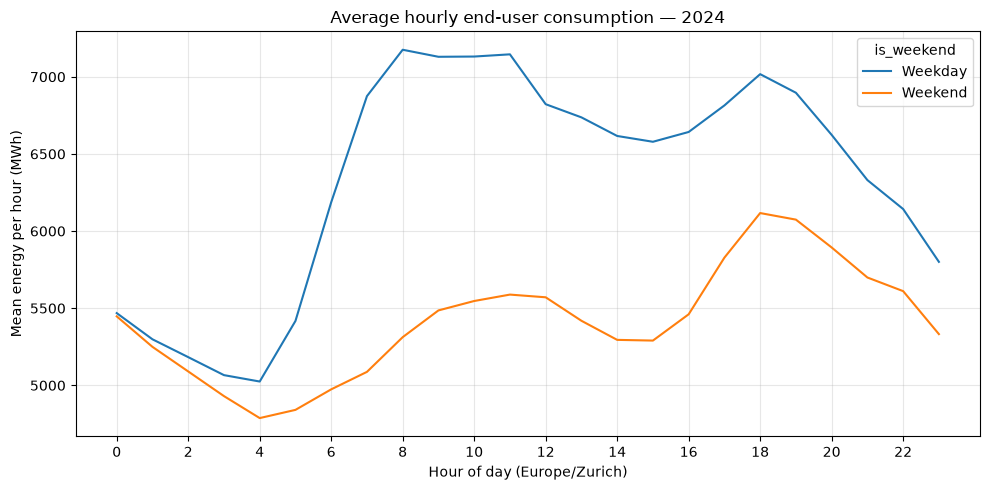

In [21]:
hourly["hour_of_day"] = hourly["hour_start_local"].dt.hour
hourly["is_weekend"] = hourly["day_of_week"] >= 5

daily_profile = (
    hourly.groupby(["hour_of_day", "is_weekend"])["end_user_energy_mwh"]
    .mean()
    .unstack("is_weekend")
    .rename(columns={False: "Weekday", True: "Weekend"})
)

ax = daily_profile.plot(figsize=(10, 5))

ax.set_title("Average hourly end-user consumption — 2024")
ax.set_xlabel("Hour of day (Europe/Zurich)")
ax.set_ylabel("Mean energy per hour (MWh)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
daily_profile["gap_mwh"] = (
    daily_profile["Weekday"] - daily_profile["Weekend"]
)

largest_gap_hour = daily_profile["gap_mwh"].idxmax()

print("Hour with largest average gap:", largest_gap_hour)
print(
    "Largest average gap:",
    round(daily_profile.loc[largest_gap_hour, "gap_mwh"], 2),
    "MWh",
)

display(daily_profile.round(2))

Hour with largest average gap: 8
Largest average gap: 1862.92 MWh


is_weekend,Weekday,Weekend,gap_mwh
hour_of_day,,,
0,5468.32,5447.20,21.12
1,5298.54,5249.52,49.02
2,5182.91,5090.12,92.79
3,5066.29,4930.34,135.96
4,5024.82,4787.91,236.91
5,5417.41,4841.09,576.32
6,6186.73,4974.17,1212.56
7,6874.51,5087.40,1787.11
8,7175.24,5312.32,1862.92


In [23]:
hourly["month"] = hourly["hour_start_local"].dt.month

monthly_summary = (
    hourly.groupby("month")["end_user_energy_mwh"]
    .agg(["mean", "min", "max", "count"])
)

with pd.option_context("display.float_format", "{:,.2f}".format):
    display(monthly_summary)

,mean,min,max,count
month,,,,
1,"7,257.81","5,083.84","9,401.33",744
2,"6,679.11","4,931.24","8,685.19",696
3,"6,303.87","4,136.24","8,306.85",743
4,"5,935.38","3,963.87","8,009.62",720
5,"5,459.77","3,960.29","7,524.78",744
6,"5,362.84","3,825.09","7,212.73",720
7,"5,182.16","3,759.53","6,916.16",744
8,"5,178.43","3,612.83","6,748.32",744
9,"5,616.00","3,812.49","7,490.23",720


In [24]:
highest_month = monthly_summary["mean"].idxmax()
lowest_month = monthly_summary["mean"].idxmin()

print("Highest-consumption month:", highest_month)
print("Lowest-consumption month:", lowest_month)

Highest-consumption month: 1
Lowest-consumption month: 8


In [25]:
assert len(hourly) == 8784, "Unexpected hourly row count."
assert hourly["interval_count"].eq(4).all(), "An hour lacks four readings."
assert hourly["end_user_energy_mwh"].notna().all(), "Missing hourly targets."
assert energy_preserved, "Total energy was not preserved."
assert len(weekday_summary) == 7, "Weekday summary is incomplete."
assert len(daily_profile) == 24, "Daily profile is incomplete."
assert len(monthly_summary) == 12, "Monthly summary is incomplete."

print("PASS: All checkpoint checks passed.")

PASS: All checkpoint checks passed.
